In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print("Dataset Information:")
print("-" * 40)

df.info()

Dataset Information:
----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB


In [3]:
print("Missing Values:")
print("-" * 40)

print(df.isnull().sum())

Missing Values:
----------------------------------------
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64


In [4]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 27


In [5]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("New dataset shape:", df.shape)

Duplicates removed successfully!
New dataset shape: (741, 7)


In [6]:
print("Cleaned dataset shape:", df.shape)

Cleaned dataset shape: (741, 7)


In [7]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [8]:
df.columns = df.columns.str.strip()

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [9]:
print("Data Types:")
print("-" * 40)

print(df.dtypes)

Data Types:
----------------------------------------
Region                                         str
Date                                           str
Frequency                                      str
Estimated Unemployment Rate (%)            float64
Estimated Employed                         float64
Estimated Labour Participation Rate (%)    float64
Area                                           str
dtype: object


In [10]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

print("Date column converted successfully!")
print(df["Date"].head())

Date column converted successfully!
0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[us]


In [11]:
print("Statistical Summary:")
print("-" * 40)

df.describe()

Statistical Summary:
----------------------------------------


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [12]:
print("Area Distribution:")
print("-" * 40)

print(df["Area"].value_counts())

Area Distribution:
----------------------------------------
Area
Urban    381
Rural    359
Name: count, dtype: int64


In [13]:
average_unemployment = df["Estimated Unemployment Rate (%)"].mean()

print(f"Average Unemployment Rate: {average_unemployment:.2f}%")

Average Unemployment Rate: 11.79%


In [14]:
region_unemployment = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Unemployment Rate by Region:")
print(region_unemployment)

Average Unemployment Rate by Region:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


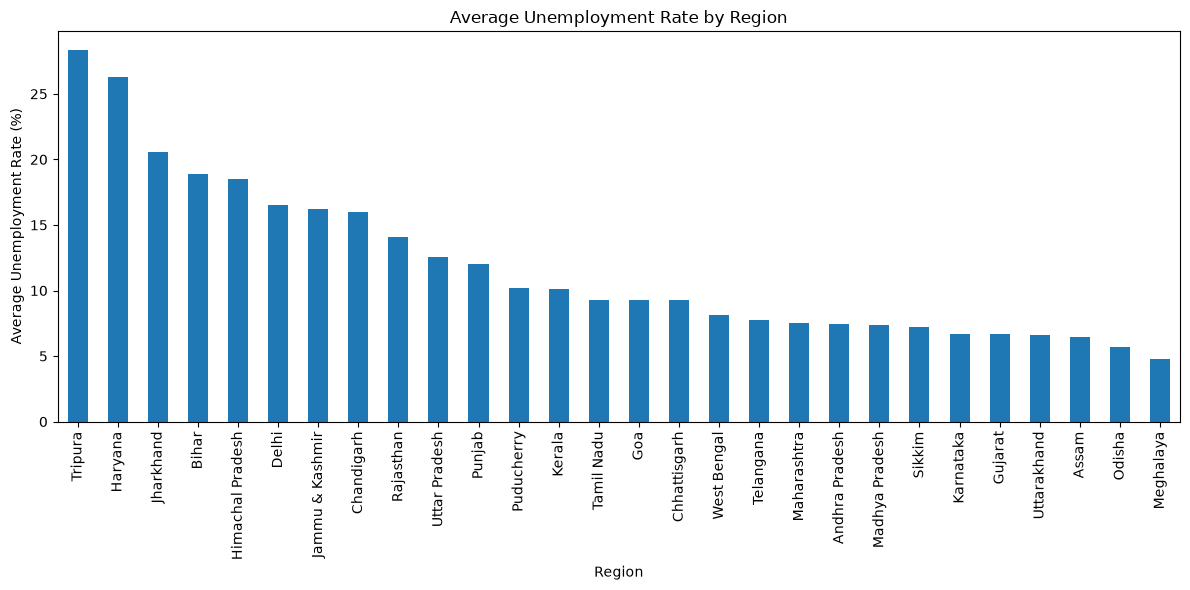

In [18]:
plt.figure(figsize=(12, 6))

region_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

In [19]:
area_unemployment = (
    df.groupby("Area")["Estimated Unemployment Rate (%)"]
    .mean()
)

print("Average Unemployment Rate by Area:")
print(area_unemployment)

Average Unemployment Rate by Area:
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


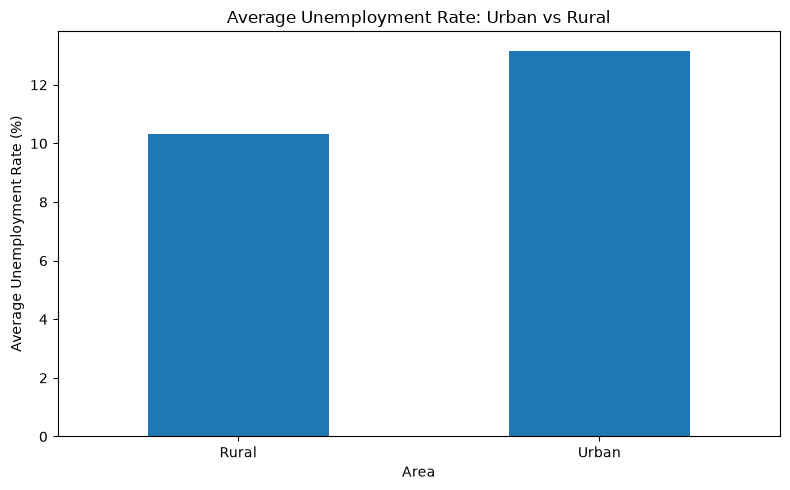

In [20]:
plt.figure(figsize=(8, 5))

area_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate: Urban vs Rural")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [21]:
monthly_unemployment = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

print("Unemployment Rate Over Time:")
print(monthly_unemployment)

Unemployment Rate Over Time:
Date
2019-05-31     8.874259
2019-06-30     9.303333
2019-07-31     9.033889
2019-08-31     9.637925
2019-09-30     9.051731
2019-10-31     9.900909
2019-11-30     9.868364
2019-12-31     9.497358
2020-01-31     9.950755
2020-02-29     9.964717
2020-03-31    10.700577
2020-04-30    23.641569
2020-05-31    24.875294
2020-06-30    11.903600
Name: Estimated Unemployment Rate (%), dtype: float64


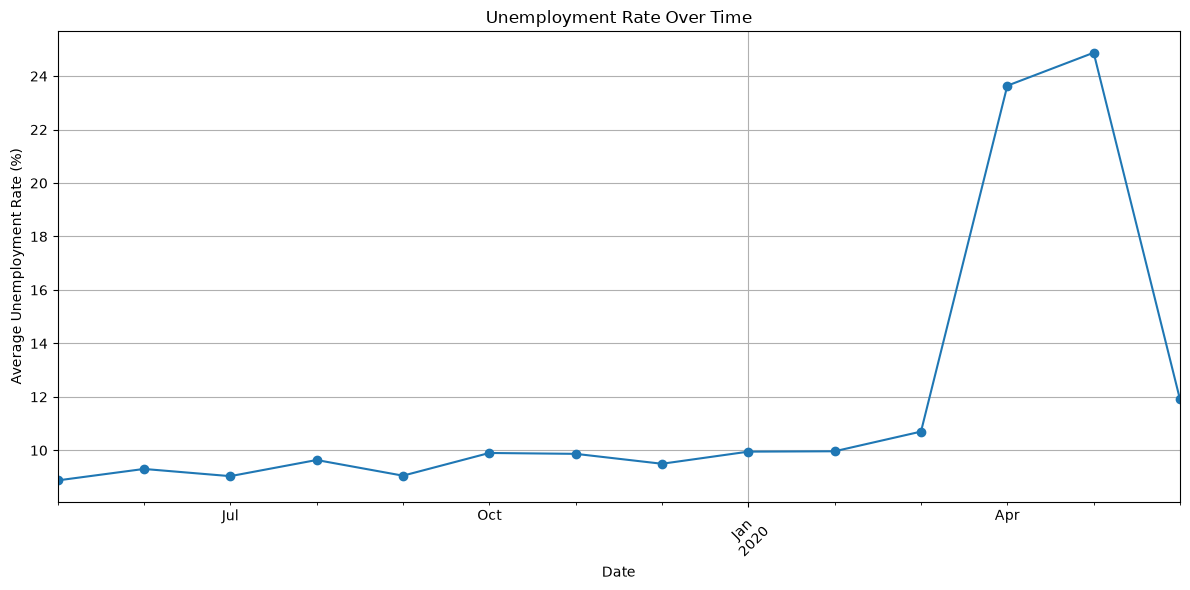

In [22]:
plt.figure(figsize=(12, 6))

monthly_unemployment.plot(kind="line", marker="o")

plt.title("Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [23]:
top_regions = region_unemployment.head(10)

print("Top 10 Regions by Average Unemployment Rate:")
print(top_regions)

Top 10 Regions by Average Unemployment Rate:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64


In [24]:
bottom_regions = region_unemployment.tail(10).sort_values()

print("10 Regions with Lowest Average Unemployment Rate:")
print(bottom_regions)

10 Regions with Lowest Average Unemployment Rate:
Region
Meghalaya         4.798889
Odisha            5.657857
Assam             6.428077
Uttarakhand       6.582963
Gujarat           6.663929
Karnataka         6.676071
Sikkim            7.249412
Madhya Pradesh    7.406429
Andhra Pradesh    7.477143
Maharashtra       7.557500
Name: Estimated Unemployment Rate (%), dtype: float64


In [25]:
employment_by_region = (
    df.groupby("Region")["Estimated Employed"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Estimated Employment by Region:")
print(employment_by_region)

Average Estimated Employment by Region:
Region
Uttar Pradesh       2.809483e+07
Maharashtra         1.999020e+07
West Bengal         1.719854e+07
Bihar               1.236619e+07
Tamil Nadu          1.226955e+07
Gujarat             1.140201e+07
Madhya Pradesh      1.111548e+07
Karnataka           1.066712e+07
Rajasthan           1.004106e+07
Andhra Pradesh      8.154093e+06
Telangana           7.939663e+06
Odisha              6.545747e+06
Assam               5.354772e+06
Punjab              4.539362e+06
Jharkhand           4.469240e+06
Kerala              4.425900e+06
Chhattisgarh        4.303499e+06
Haryana             3.557072e+06
Delhi               2.627513e+06
Jammu & Kashmir     1.799932e+06
Uttarakhand         1.390228e+06
Himachal Pradesh    1.059824e+06
Tripura             7.170026e+05
Meghalaya           6.897368e+05
Chandigarh          3.168312e+05
Goa                 2.263083e+05
Puducherry          2.122781e+05
Sikkim              1.068807e+05
Name: Estimated Employed, dty

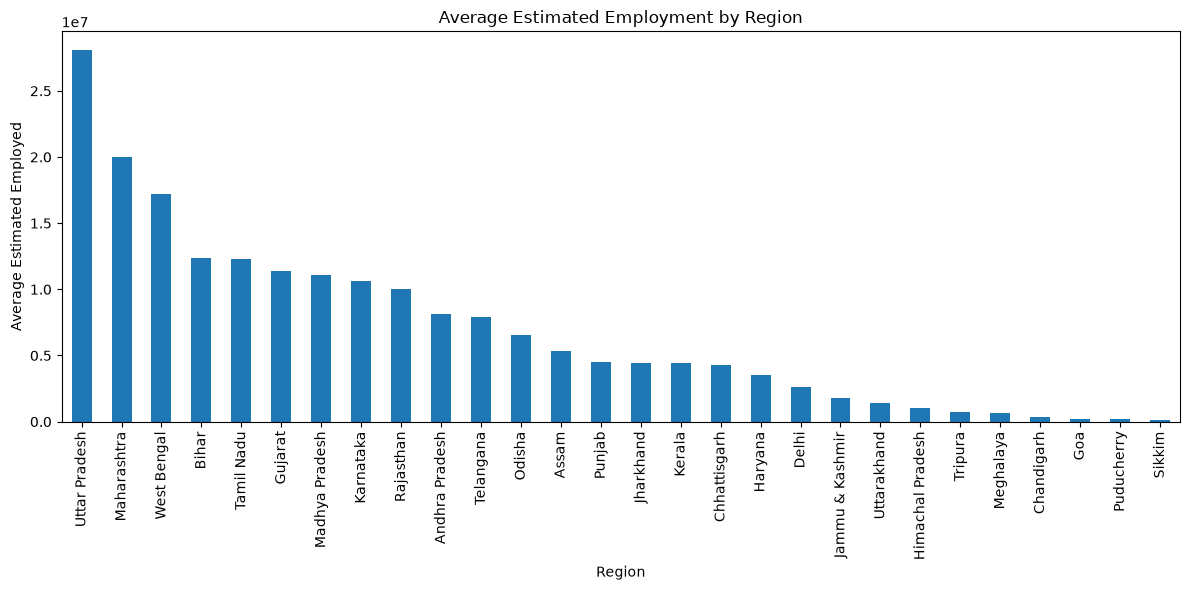

In [26]:
plt.figure(figsize=(12, 6))

employment_by_region.plot(kind="bar")

plt.title("Average Estimated Employment by Region")
plt.xlabel("Region")
plt.ylabel("Average Estimated Employed")
plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

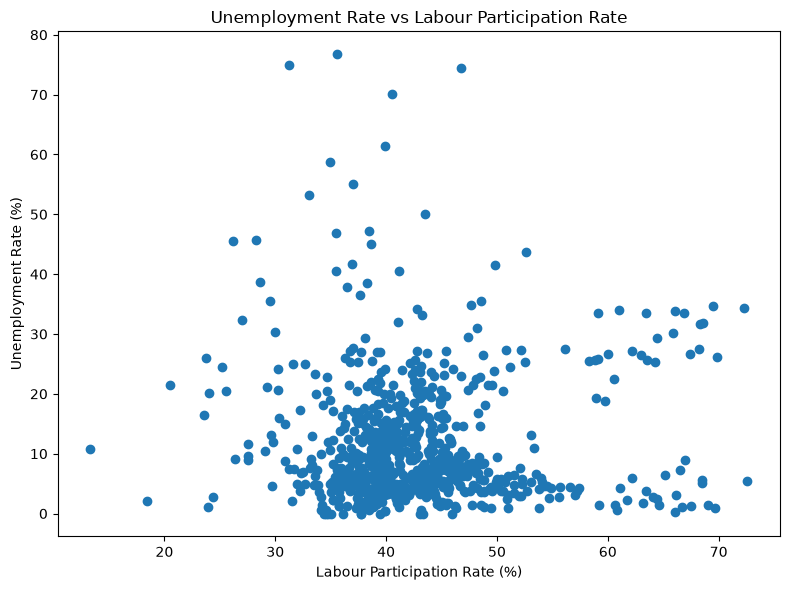

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Estimated Labour Participation Rate (%)"],
    df["Estimated Unemployment Rate (%)"]
)

plt.title("Unemployment Rate vs Labour Participation Rate")
plt.xlabel("Labour Participation Rate (%)")
plt.ylabel("Unemployment Rate (%)")
plt.tight_layout()

plt.show()

In [28]:
correlation = df[
    [
        "Estimated Labour Participation Rate (%)",
        "Estimated Unemployment Rate (%)"
    ]
].corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                                         Estimated Labour Participation Rate (%)  \
Estimated Labour Participation Rate (%)                                 1.000000   
Estimated Unemployment Rate (%)                                         0.002558   

                                         Estimated Unemployment Rate (%)  
Estimated Labour Participation Rate (%)                         0.002558  
Estimated Unemployment Rate (%)                                 1.000000  


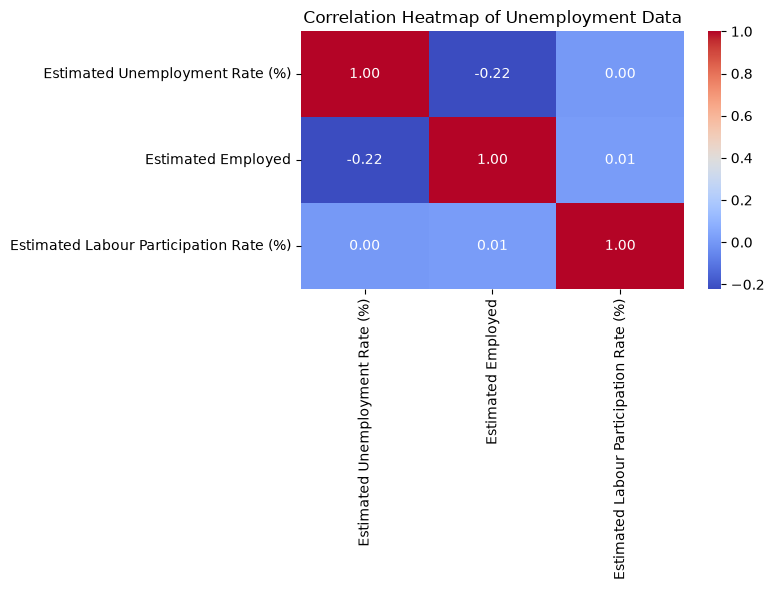

In [29]:
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Unemployment Data")
plt.tight_layout()

plt.show()

In [30]:
print("UNEMPLOYMENT ANALYSIS - FINAL SUMMARY")
print("=" * 50)

print(f"Total records after cleaning: {len(df)}")
print(f"Average unemployment rate: {average_unemployment:.2f}%")

print("\nHighest average unemployment regions:")
print(top_regions)

print("\nLowest average unemployment regions:")
print(bottom_regions)

print("\nAverage unemployment by area:")
print(area_unemployment)

print("\nCorrelation between unemployment and labour participation:")
print(correlation.loc[
    "Estimated Unemployment Rate (%)",
    "Estimated Labour Participation Rate (%)"
])

UNEMPLOYMENT ANALYSIS - FINAL SUMMARY
Total records after cleaning: 741
Average unemployment rate: 11.79%

Highest average unemployment regions:
Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64

Lowest average unemployment regions:
Region
Meghalaya         4.798889
Odisha            5.657857
Assam             6.428077
Uttarakhand       6.582963
Gujarat           6.663929
Karnataka         6.676071
Sikkim            7.249412
Madhya Pradesh    7.406429
Andhra Pradesh    7.477143
Maharashtra       7.557500
Name: Estimated Unemployment Rate (%), dtype: float64

Average unemployment by area:
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float